<a href="https://colab.research.google.com/github/Raghavendra1435/portfolio/blob/main/analysisproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**iam Raghavendra Pothula**

***iam exicited  to share my new Mini Data Analysis Project***

**Questions**

**i have chosen Titanic Dataset.For Titanic dataset,i had raise three good questions:**

1. **Did women have a higher survival rate than men?**
2. **Did passenger class affect survival?**
3. **Did age affect survival, and did the effect differ by sex?**


**The Seaborn Python library has around 22 built-in example datasets in its current commonly used dataset collection** for my project i taken this Titanic dataset- well known, small, and rich enough to ask interesting questions.

In [6]:
import warnings
warnings.filterwarnings("ignore")
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Step 1:Inspect Before You Touch**

Always begin by looking at what you have.

In [4]:
df.shape
df.info()
df.describe()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


**You will notice that age has 177 missing values, and embarked has a couple.**

For this project we will keep age as-is (pandas skips NaN for .mean() automatically) and ignore the two missing embarked values.

Next..Iam using Hisplot, to understand the distribution of data visually we wil use Histogram.

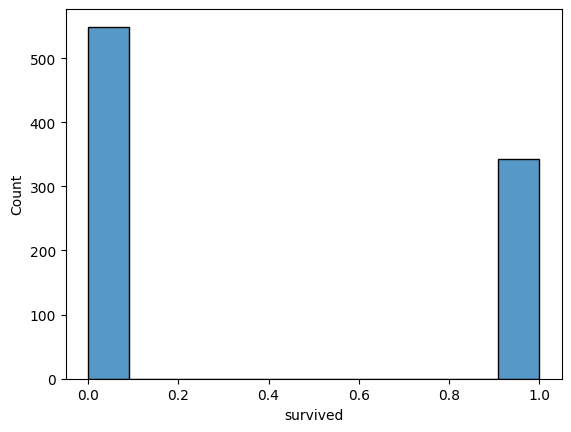

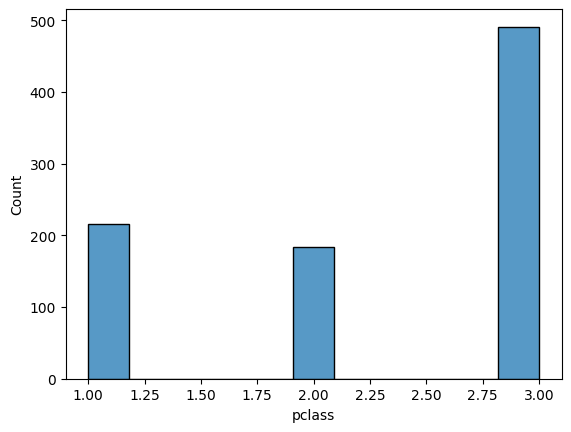

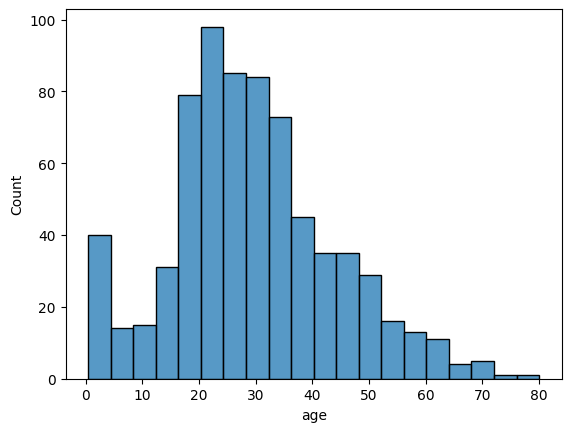

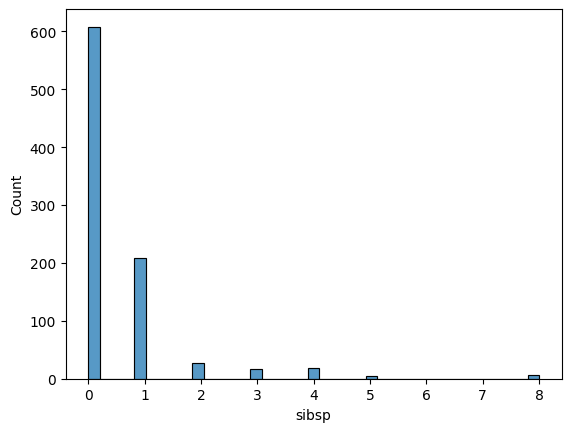

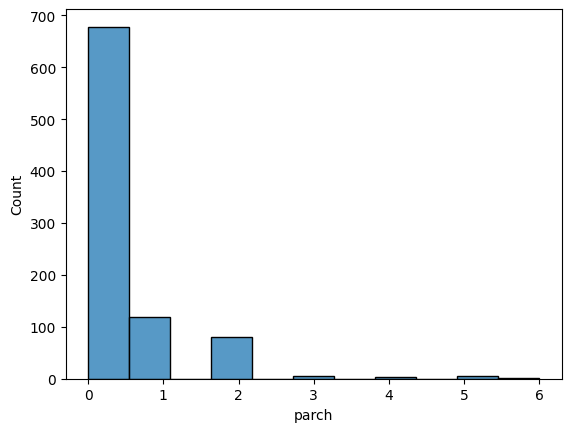

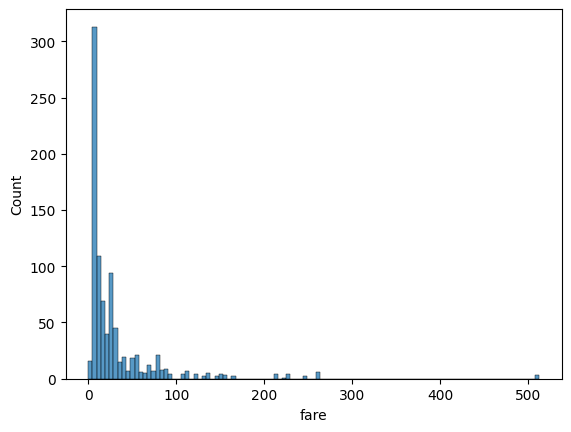

In [7]:
for i in df.select_dtypes(include="number").columns:
    sns.histplot(data=df,x=i)
    plt.show()

**Step 2: Missing Values Treatment**   

 *i choosen median method of impute missing value, because my data is continuous or numerical thats why we can fill it with "median". and i already mentioned that ,this dataset has null values in "age" and "embarked".*

In [24]:
num_cols = ["age", "fare", "sibsp", "parch", "pclass"]
cat_cols = ["embarked"]

for i in ["age","embarked"]:
    df["age"] = df["age"].fillna(df["age"].median())
    df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
from sklearn.impute import KNNImputer, SimpleImputer
knn = KNNImputer(n_neighbors=5)
df[num_cols] = knn.fit_transform(df[num_cols])
for i in cat_cols:
    imp = SimpleImputer(strategy="most_frequent")
    df[[i]] = imp.fit_transform(df[[i]])

print(df[["age", "fare", "embarked"]].isnull().sum())

age         0
fare        0
embarked    0
dtype: int64


sex
female    0.742038
male      0.188908
Name: survived, dtype: float64


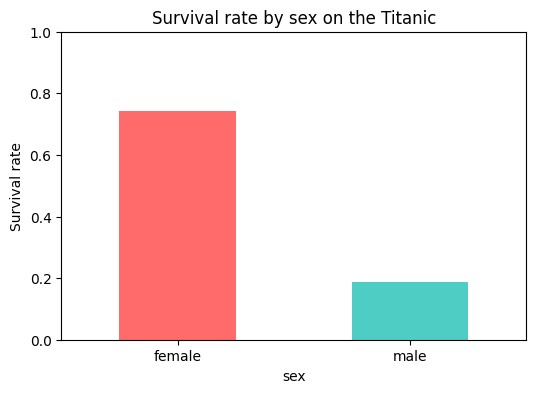

In [25]:
##Question 1: Survival by sex

import matplotlib.pyplot as plt

survival_by_sex = df.groupby("sex")["survived"].mean()
print(survival_by_sex)

ax = survival_by_sex.plot(kind="bar", figsize=(6, 4), color=["#ff6b6b", "#4ecdc4"])
ax.set_ylabel("Survival rate")
ax.set_title("Survival rate by sex on the Titanic")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

**You will see female survival around 74 percent and male around 19 percent. Striking.**

class
First     0.629630
Second    0.472826
Third     0.242363
Name: survived, dtype: float64


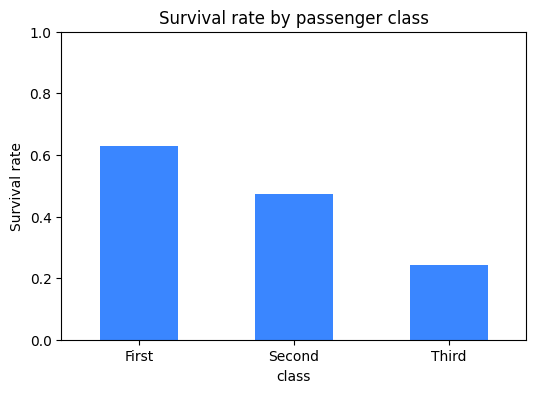

In [26]:
##Question 2: Survival by class

survival_by_class = df.groupby("class")["survived"].mean().reindex(["First", "Second", "Third"])
print(survival_by_class)

ax = survival_by_class.plot(kind="bar", figsize=(6, 4), color="#3a86ff")
ax.set_ylabel("Survival rate")
ax.set_title("Survival rate by passenger class")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

**First class around 63 percent, second around 47 percent, third around 24 percent. Class matters.**

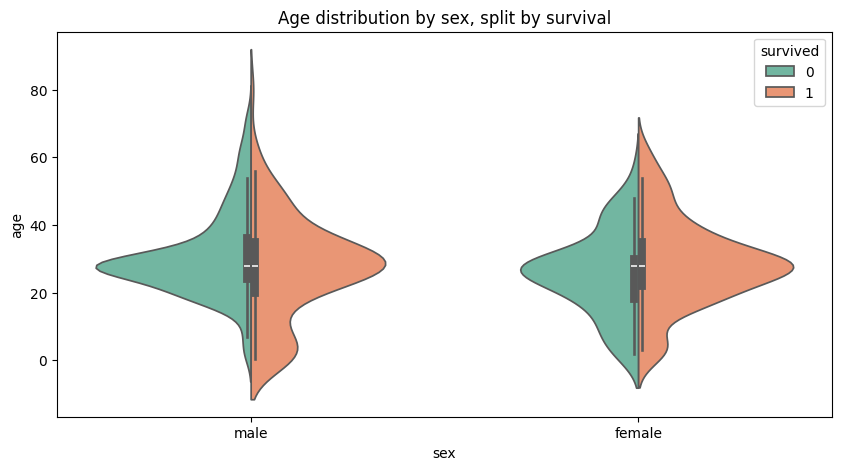

In [27]:
##Question 3: Age and sex combined

import seaborn as sns

plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x="sex", y="age", hue="survived", split=True, palette="Set2")
plt.title("Age distribution by sex, split by survival")
plt.show()

**A violin plot shows the distribution. You will see that young children (under 10) survived at much higher rates regardless of sex, and that older men were the least likely to survive. Compare the shapes**

**Final Summary**

**Sex was the strongest predictor of survival**- * Women survived at roughly
74 percent, men at roughly 19 percent — a gap of 55 points.*

**Class amplified the gap**- *Among first-class passengers, the survival rate was 63 percent; among third-class, only 24 percent.*

**Children survived at higher rates regardless of sex**- *Passengers under 10 had visibly higher survival in both sexes.*

**Limitations**- *Age is missing for 177 passengers, so the age-based conclusion is based on the 80 percent of records where age is known.*